# TASK 3: Data Analysis & Visualization
This notebook processes raw logs, calculates confidence intervals, and generates publication-ready plots.

In [1]:
import numpy as np
import pandas as pd
import subprocess
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

np.random.seed(42)
print("Random seed fixed to 42.")

Random seed fixed to 42.


## 1. Data Processing & Warm-up Filtering
We run the `process_data.py` script which loads raw `.jsonl` logs, drops the cold-start warm-up phase, and performs bootstrapping.

In [2]:
import subprocess
result = subprocess.run([sys.executable, str(PROJECT_ROOT / "src/process_data.py"), "--raw", str(PROJECT_ROOT / "data/raw"), "--out", str(PROJECT_ROOT / "data/processed")], capture_output=True, text=True, cwd=PROJECT_ROOT, check=True)
print(result.stdout)

import pandas as pd
metrics = pd.read_csv(PROJECT_ROOT / "data/processed/metrics_summary.csv")
metrics[["detector", "f1", "f1_ci95_lo", "f1_ci95_hi", "fpr_human"]]

                                        0                  1                2                      3
detector                    ensemble_mean  lexical_formality  random_baseline  stylometric_heuristic
n_test_docs                           329                329              329                    329
f1                                  0.917              0.795            0.157                  0.924
f1_boot_mean                        0.917              0.794            0.156                  0.924
f1_boot_sd                          0.015              0.024            0.033                  0.014
f1_ci95_lo                          0.888              0.746            0.093                  0.893
f1_ci95_hi                          0.945              0.842            0.222                   0.95
auroc                               0.969              0.889            0.489                  0.979
auroc_boot_mean                     0.969              0.888             0.49              

,detector,f1,f1_ci95_lo,f1_ci95_hi,fpr_human
0,ensemble_mean,0.917333,0.887528,0.944882,0.100000
1,lexical_formality,0.795322,0.746269,0.841815,0.121429
2,random_baseline,0.156682,0.093447,0.222222,0.078571
3,stylometric_heuristic,0.924324,0.892644,0.950131,0.071429


## 2. Scientific Visualization
Generating plots with 95% CI bands, log scales, and colorblind-safe palettes.

In [3]:
import subprocess
result = subprocess.run([sys.executable, str(PROJECT_ROOT / "src/visualize.py")], capture_output=True, text=True, cwd=PROJECT_ROOT, check=True)
print(result.stdout)

Графики успешно сохранены в reports\figures!



F1 Distribution:


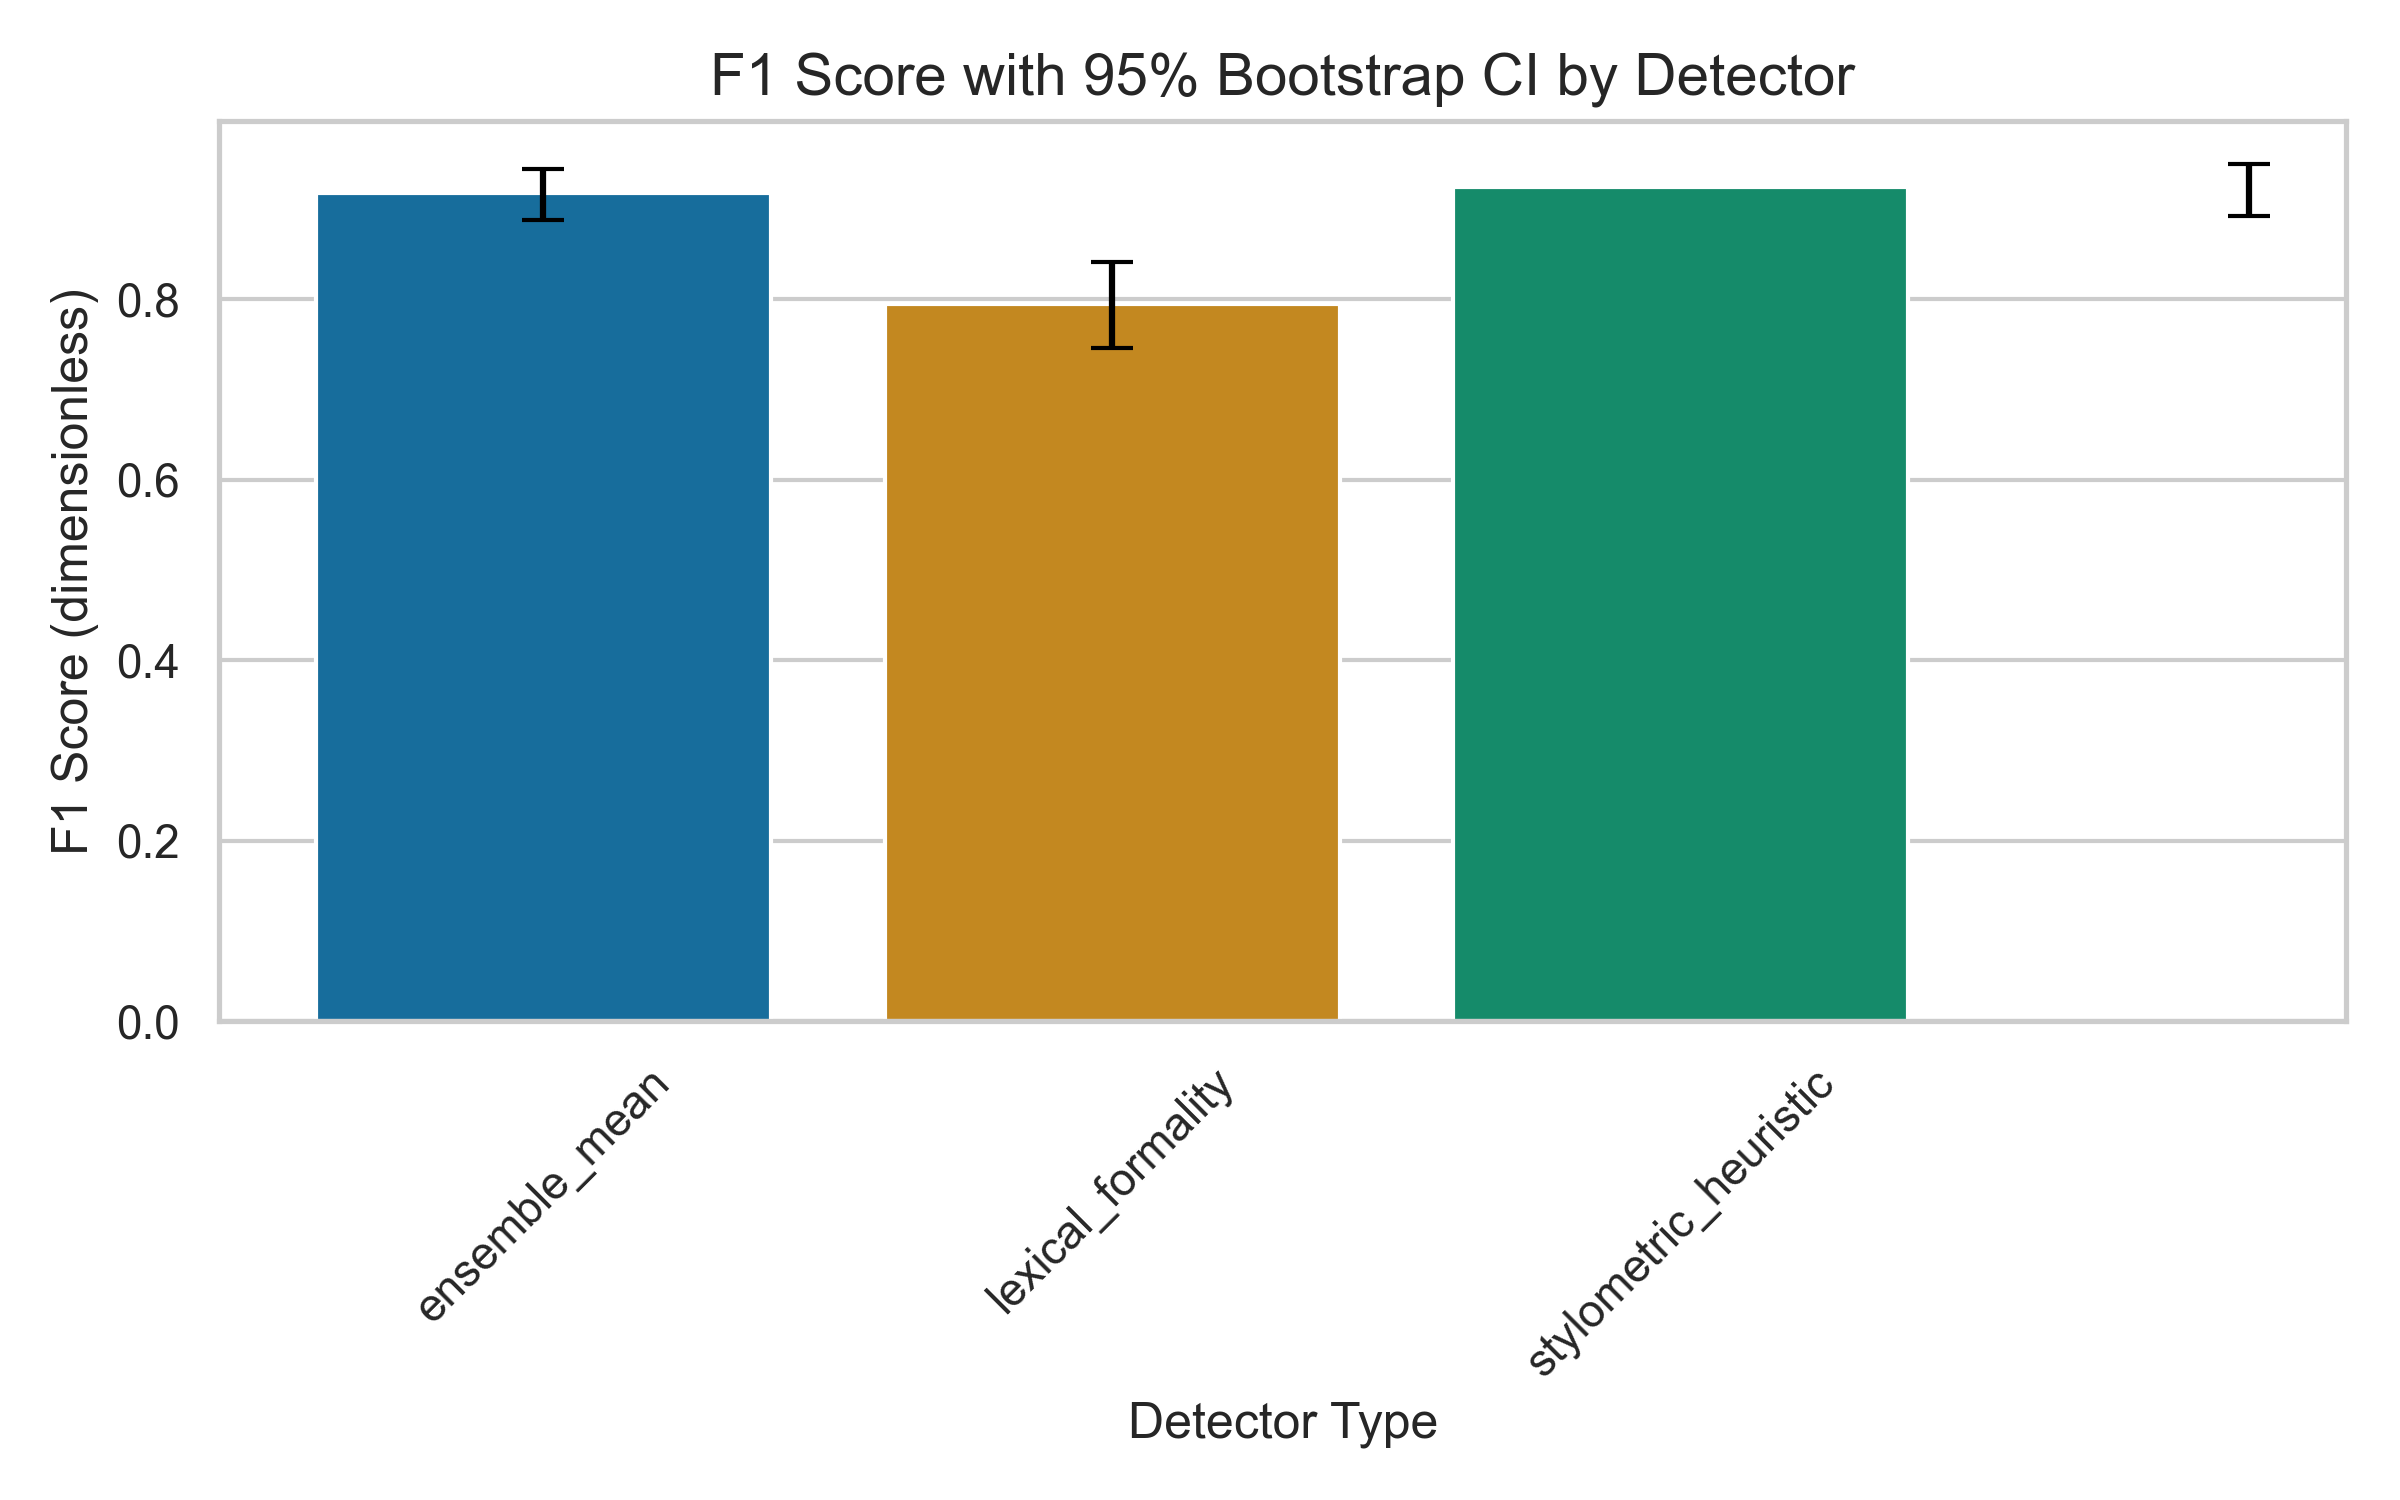

Latency vs Load:


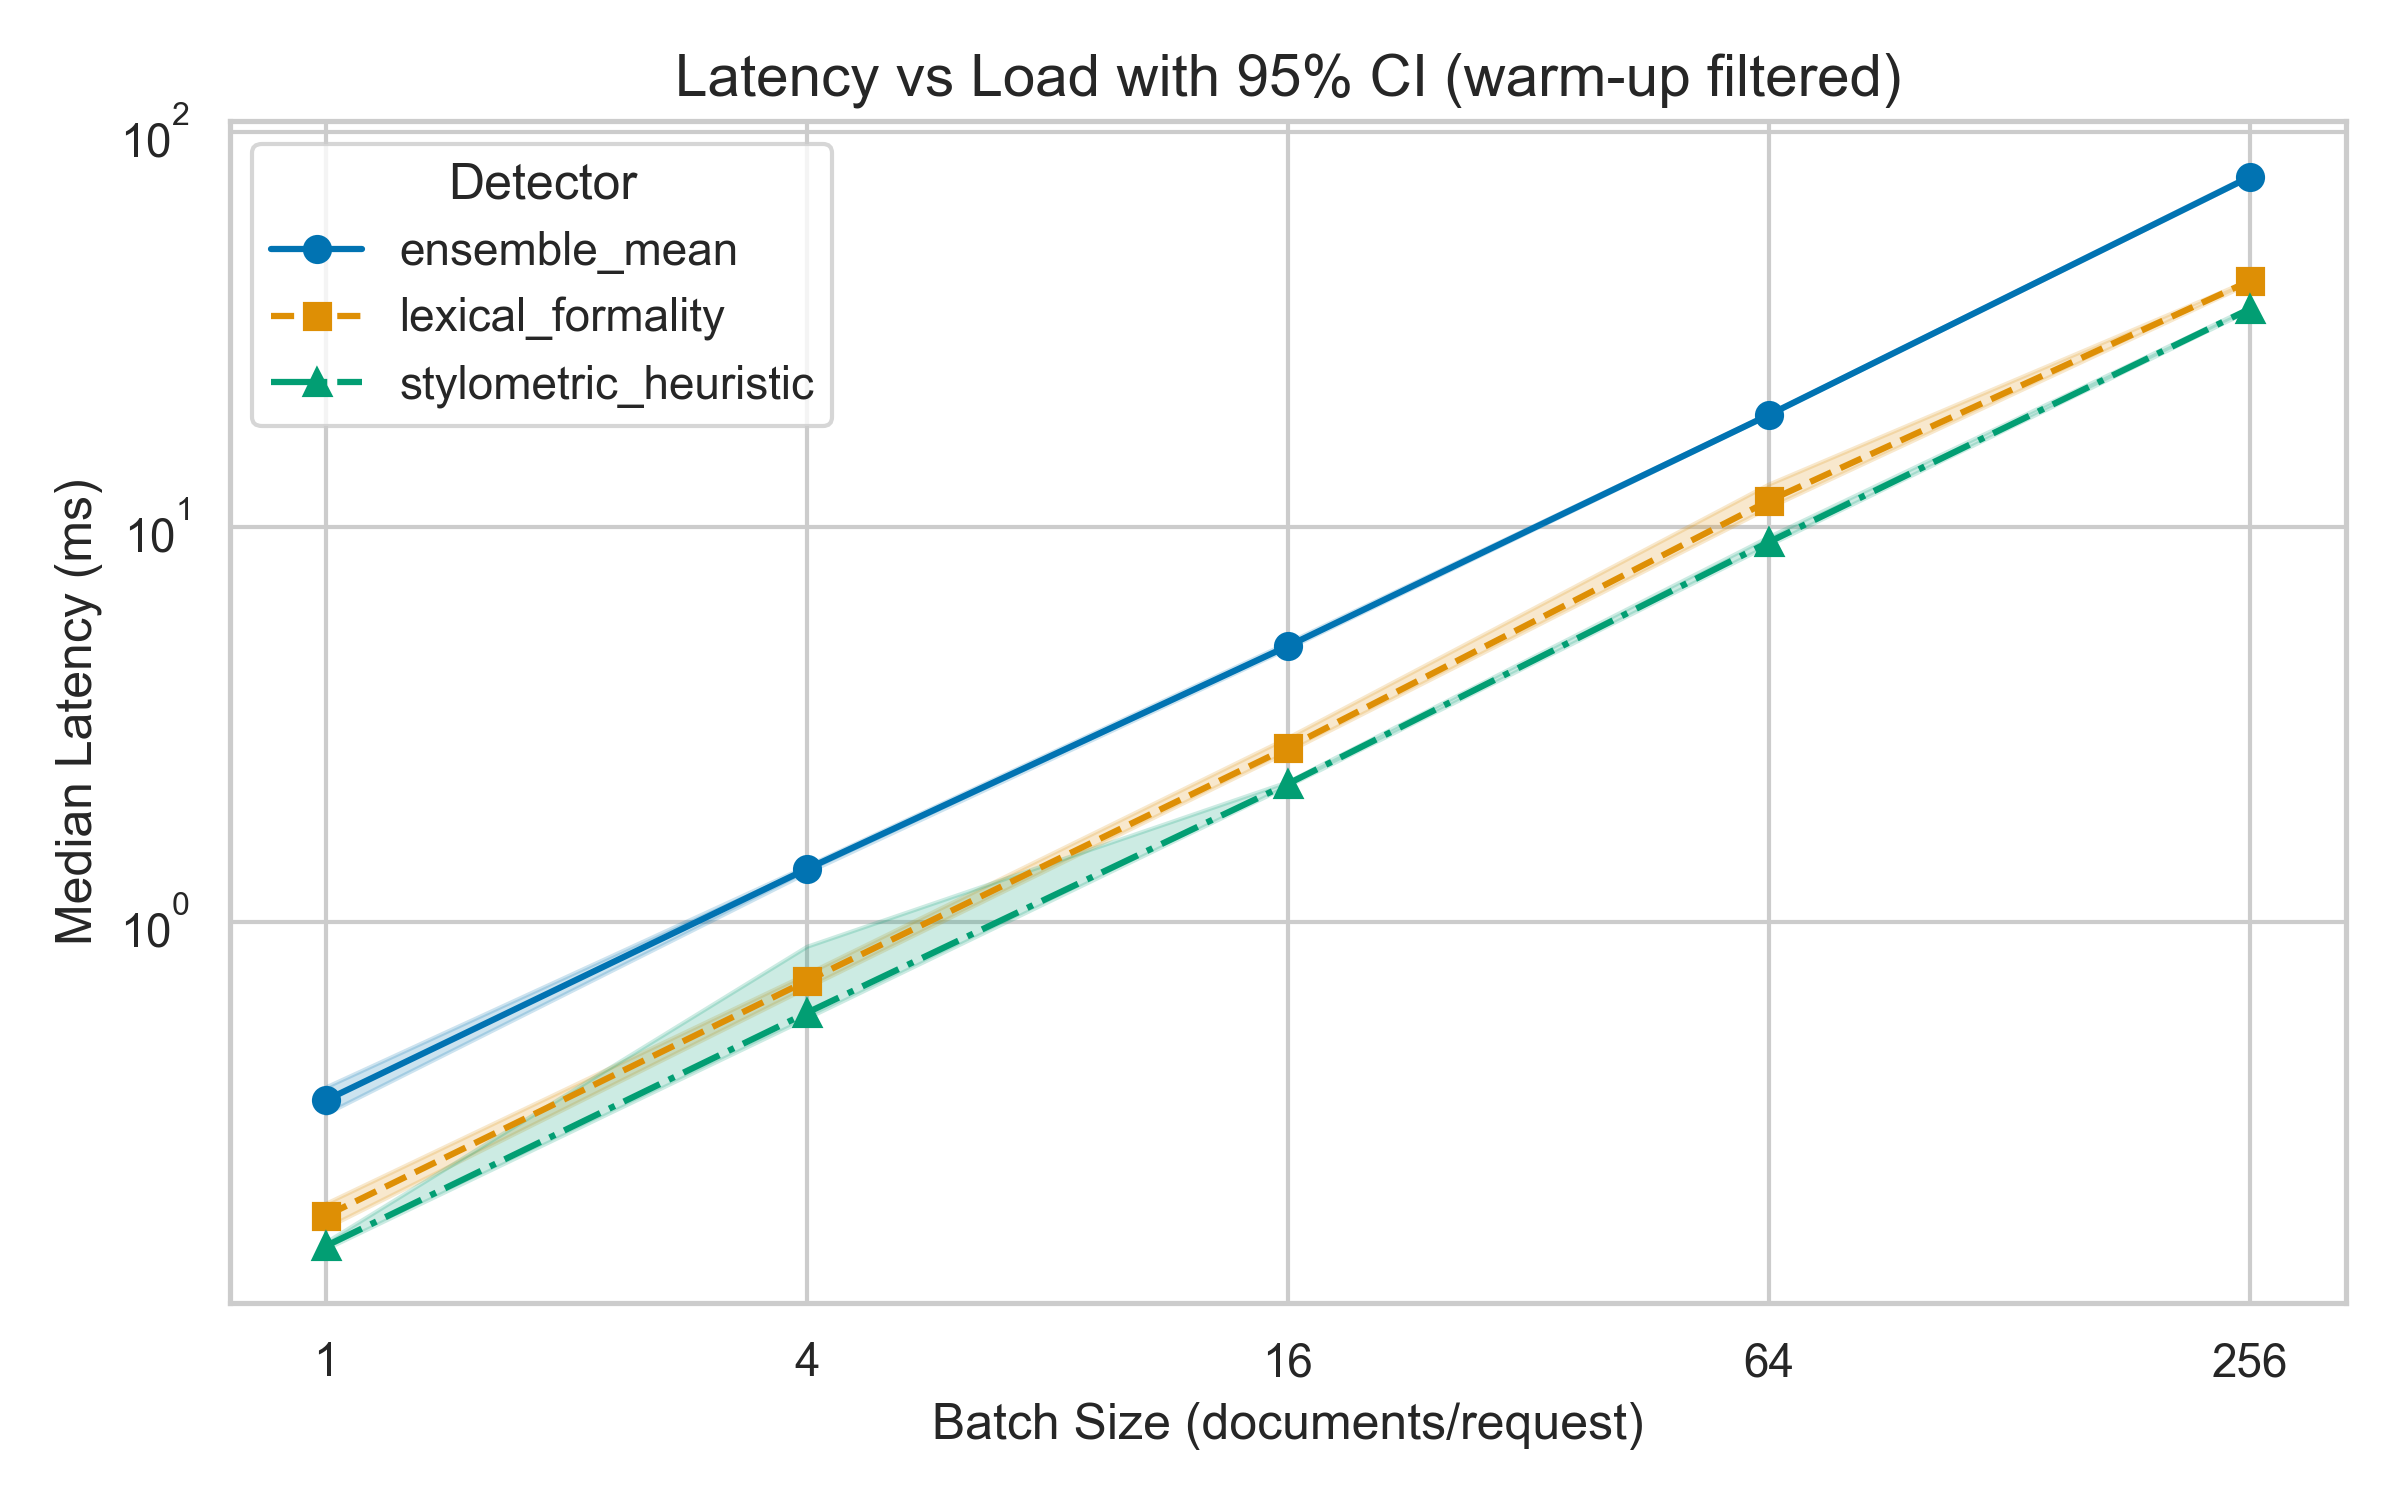

In [4]:
from IPython.display import Image, display
print("F1 Distribution:")
display(Image(filename=str(PROJECT_ROOT / "reports/figures/fig1_distribution_boxplot.png")))
print("Latency vs Load:")
display(Image(filename=str(PROJECT_ROOT / "reports/figures/fig2_latency_vs_load.png")))